# 05. Baseline and Comparative Modelling (Training Set Only, Cross-Validated)

## Objective
Estimate how well non-kidney-measure predictors identify existing kidney abnormality markers (eGFR < 60 or UACR ≥ 30 mg/g) among US adults with diabetes, and compare Logistic Regression, Random Forest and XGBoost under identical conditions.

## Design and safeguards
- **Input:** `data/processed/train.csv` (n = 1,246). The test set (n = 312) is not used in this notebook.
- **Validation:** 5-fold stratified CV repeated 3 times (15 folds), `random_state=42`. The same `cv` object is reused for every model so comparisons are fair.
- **Leakage control:** Imputation, scaling and encoding sit inside a scikit-learn `Pipeline`, so they are fitted only on each fold's training portion.
- **Features:** age, sex, income-to-poverty ratio, HbA1c, BMI, systolic and diastolic BP, insulin use, smoking status. Outcome-defining variables (creatinine, urine albumin, UACR, eGFR) are excluded.
- **Interpretation limits:** Cross-sectional associations only. Not a diagnostic tool, not a prediction of future CKD, and not survey-weighted.

## 1. Load training data and verify the preprocessor

**Purpose:** Confirm the preprocessing module produces a complete numeric matrix before it is used in modelling.
**Method:** Median imputation with missing-indicator flags and standard scaling for numeric variables; pass-through for binary variables; one-hot encoding for smoking status.
**Check:** 17 output columns, no remaining NaN.

In [30]:
import sys
sys.path.append("..")
import pandas as pd, numpy as np
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

train = pd.read_csv("../data/processed/train.csv")
X = train[NUMERIC + BINARY + CATEGORICAL]
y = train[TARGET].astype(int)

In [31]:
import sys
sys.path.append("..")
import pandas as pd, numpy as np
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

train = pd.read_csv("../data/processed/train.csv")
X = train[NUMERIC + BINARY + CATEGORICAL]
y = train[TARGET]

pre = build_preprocessor()
Xt = pre.fit_transform(X)
print(Xt.shape)
print(pre.get_feature_names_out())
print("NaN left:", np.isnan(Xt).sum())

(1246, 17)
['num__RIDAGEYR' 'num__INDFMPIR' 'num__LBXGH' 'num__BMXBMI' 'num__BPXOSY1'
 'num__BPXODI1' 'num__missingindicator_INDFMPIR'
 'num__missingindicator_LBXGH' 'num__missingindicator_BMXBMI'
 'num__missingindicator_BPXOSY1' 'num__missingindicator_BPXODI1'
 'bin__female' 'bin__insulin' 'cat__smoking_current' 'cat__smoking_former'
 'cat__smoking_never' 'cat__smoking_unknown']
NaN left: 0


### Interpretation
The transformed matrix has 1,246 rows and 17 columns (6 numeric, 5 missing-indicators, 2 binary, 4 smoking categories) with no NaN. Missing-indicators exist only for variables with missing training values (age has none). The two blood-pressure indicators are identical because both readings are missing for the same participants (redundant but harmless). `smoking_unknown` contains only 2 participants and carries negligible information. This fit on the whole training set is a shape check only; in modelling the preprocessor is refitted inside each fold.

## 2. Baseline models

**Purpose:** Establish reference performance. A prior-only dummy classifier shows the score of "no skill", and regularised logistic regression is the interpretable benchmark for a sample of this size.
**Method:** Repeated stratified 5-fold CV (3 repeats). Metrics: ROC-AUC, recall, precision, F1 (default 0.5 threshold), reported as mean ± SD across 15 folds.
**Expected behaviour:** The dummy model yields ROC-AUC 0.5 and zero recall and precision, because it never predicts a positive. The associated precision warnings are expected.

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

y = train[TARGET].astype(int)          # make sure labels are 0/1 integers
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = ["roc_auc", "recall", "precision", "f1"]

models = {
    "dummy": DummyClassifier(strategy="prior"),
    "logreg": LogisticRegression(max_iter=1000, C=1.0),
}

for name, m in models.items():
    pipe = Pipeline([("pre", build_preprocessor()), ("model", m)])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    print(name, {s: f"{res['test_'+s].mean():.3f} ± {res['test_'+s].std():.3f}"
                 for s in scoring})

dummy {'roc_auc': '0.500 ± 0.000', 'recall': '0.000 ± 0.000', 'precision': '0.000 ± 0.000', 'f1': '0.000 ± 0.000'}
logreg {'roc_auc': '0.726 ± 0.025', 'recall': '0.506 ± 0.059', 'precision': '0.651 ± 0.036', 'f1': '0.567 ± 0.041'}


### Interpretation
| Model | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|
| Dummy (prior) | 0.500 ± 0.000 | 0.000 | 0.000 | 0.000 |
| Logistic regression | 0.726 ± 0.025 | 0.506 ± 0.059 | 0.651 ± 0.036 | 0.567 ± 0.041 |

The dummy model behaves as expected, which validates the evaluation pipeline. Logistic regression discriminates moderately (AUC 0.73). A modest AUC is plausible, because the outcome is defined by creatinine and urine albumin, which are deliberately excluded, so the model relies on indirect correlates (age, blood pressure, glycaemic control, insulin use). At the default 0.5 threshold recall is about 0.51, meaning roughly half of participants with a kidney marker are missed. Because missed cases are the priority, threshold selection will be performed later using out-of-fold predictions on the training data, not the test set. These are unweighted associations, not causal effects.

## 3. Model comparison: Logistic Regression, Random Forest, XGBoost

**Purpose:** Compare model families fairly on the same folds and preprocessing.
**Method:** Identical `cv` splits; tree models receive unscaled inputs; hyperparameters are deliberately conservative for n ≈ 1,250 (forest: `min_samples_leaf=10`; XGBoost: `max_depth=3`, `min_child_weight=5`, `reg_lambda=5`, `learning_rate=0.05`). No tuning has been done yet, so these are untuned comparisons.
**Risks:** Flexible models overfit small samples. Differences smaller than the fold-to-fold SD should not be treated as real.

In [33]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models2 = {
    "logreg": (LogisticRegression(max_iter=1000, C=1.0), True),
    "random_forest": (RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10, max_features="sqrt",
        random_state=42, n_jobs=-1), False),
    "xgboost": (XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        reg_lambda=5, eval_metric="logloss", random_state=42), False),
}

rows = []
for name, (m, scale) in models2.items():
    pipe = Pipeline([("pre", build_preprocessor(scale=scale)), ("model", m)])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 **{s: f"{res['test_'+s].mean():.3f} ± {res['test_'+s].std():.3f}"
                    for s in scoring}})
print(pd.DataFrame(rows).to_string(index=False))

        model       roc_auc        recall     precision            f1
       logreg 0.726 ± 0.025 0.506 ± 0.059 0.651 ± 0.036 0.567 ± 0.041
random_forest 0.703 ± 0.024 0.482 ± 0.044 0.640 ± 0.033 0.548 ± 0.032
      xgboost 0.694 ± 0.031 0.508 ± 0.059 0.610 ± 0.047 0.553 ± 0.046


compare Random Forest and XGBoost on the same folds

In [34]:
import warnings
warnings.filterwarnings("ignore")          # hides the harmless precision warnings

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models2 = {
    "logreg": (LogisticRegression(max_iter=1000, C=1.0), True),
    "random_forest": (RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10, max_features="sqrt",
        random_state=42, n_jobs=-1), False),
    "xgboost": (XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        reg_lambda=5, eval_metric="logloss", random_state=42), False),
}

rows = []
for name, (m, scale) in models2.items():
    pipe = Pipeline([("pre", build_preprocessor(scale=scale)), ("model", m)])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 **{s: f"{res['test_'+s].mean():.3f} ± {res['test_'+s].std():.3f}"
                    for s in scoring}})
print(pd.DataFrame(rows).to_string(index=False))

        model       roc_auc        recall     precision            f1
       logreg 0.726 ± 0.025 0.506 ± 0.059 0.651 ± 0.036 0.567 ± 0.041
random_forest 0.703 ± 0.024 0.482 ± 0.044 0.640 ± 0.033 0.548 ± 0.032
      xgboost 0.694 ± 0.031 0.508 ± 0.059 0.610 ± 0.047 0.553 ± 0.046


### Interpretation
| Model | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|
| Logistic regression | 0.726 ± 0.025 | 0.506 ± 0.059 | 0.651 ± 0.036 | 0.567 ± 0.041 |
| Random forest | 0.703 ± 0.024 | 0.482 ± 0.044 | 0.640 ± 0.033 | 0.548 ± 0.032 |
| XGBoost | 0.694 ± 0.031 | 0.508 ± 0.059 | 0.610 ± 0.047 | 0.553 ± 0.046 |

Logistic regression had the highest mean ROC-AUC (0.726), followed by random forest (0.703) and XGBoost (0.694). The gap between logistic regression and XGBoost (0.032) is about one fold-level SD, so the evidence for a difference is weak. Because the 15 folds share overlapping training data, the SDs understate true uncertainty, and I do not claim any model is definitively better. Logistic regression is at least as good as the more flexible models, which is plausible for a small sample (n = 1,246) with few, mostly monotonic predictors. At the default 0.5 threshold all three models miss about half of the participants with a kidney marker (recall

##  Threshold selection using out-of-fold predictions

**Purpose:** The default 0.5 cutoff misses about half of the participants with a kidney marker. We examine the recall/precision trade-off across thresholds to choose a cutoff that prioritises recall.
**Method:** 5-fold stratified `cross_val_predict` (one pass, seed 42) gives each training participant a probability from a model that never saw that participant. The threshold is chosen on these training predictions only. The test set is untouched.
**Risk:** Choosing a threshold targets a recall level, and every gain in recall costs precision (more false positives).

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, roc_auc_score

pipe = Pipeline([("pre", build_preprocessor()),
                 ("model", LogisticRegression(max_iter=1000, C=1.0))])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(pipe, X, y, cv=skf, method="predict_proba")[:, 1]

print("OOF ROC-AUC:", round(roc_auc_score(y, oof), 3))
rows = []
for t in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    pred = (oof >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": round(recall_score(y, pred), 3),
                 "precision": round(precision_score(y, pred), 3),
                 "flagged_%": round(pred.mean() * 100, 1),
                 "missed": int(((pred == 0) & (y == 1)).sum())})
print(pd.DataFrame(rows).to_string(index=False))

OOF ROC-AUC: 0.724
 threshold  recall  precision  flagged_%  missed
      0.50   0.510      0.649       33.4     259
      0.45   0.594      0.606       41.6     215
      0.40   0.675      0.587       48.8     172
      0.35   0.747      0.550       57.6     134
      0.30   0.839      0.514       69.3      85
      0.25   0.890      0.491       77.0      58


### Interpretation
Out-of-fold ROC-AUC (0.724) agrees with the repeated-CV estimate (0.726). Lowering the threshold raises recall from 0.51 (0.50) to 0.84 (0.30) and 0.89 (0.25), reducing missed cases from 259 to 85 and 58 of about 529 participants with a marker. The cost is precision, which falls from 0.65 to 0.51 and 0.49, and the share flagged rises from 33% to 69% and 77%. Because the outcome prevalence is 42.5%, precision at the lowest thresholds is only modestly above chance, so high-recall operation is close to flagging most participants. The choice of threshold is a value judgement about the relative cost of missed cases versus unnecessary testing, not a statistical fact. These are unweighted training-set estimates and will be re-evaluated once on the untouched test set.

Chosen threshold: 0.32
 threshold  recall  precision  specificity  flagged_%
      0.32   0.802      0.529        0.474     64.286


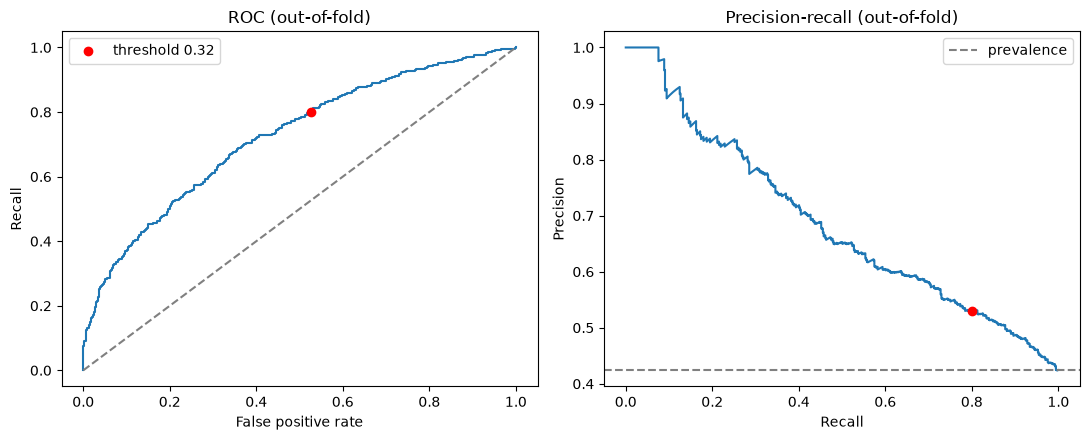

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

rows = []
for t in np.arange(0.20, 0.61, 0.01):
    pred = (oof >= t).astype(int)
    rows.append({"threshold": round(t, 2),
                 "recall": recall_score(y, pred),
                 "precision": precision_score(y, pred),
                 "specificity": recall_score(y, pred, pos_label=0),
                 "flagged_%": pred.mean() * 100})
tab = pd.DataFrame(rows)

chosen = tab[tab.recall >= 0.80].threshold.max()   # pre-specified rule
print("Chosen threshold:", chosen)
print(tab[tab.threshold == chosen].round(3).to_string(index=False))

fpr, tpr, _ = roc_curve(y, oof)
prec, rec, _ = precision_recall_curve(y, oof)
pick = tab[tab.threshold == chosen].iloc[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", color="grey")
ax[0].scatter(1 - pick.specificity, pick.recall, color="red", zorder=3, label=f"threshold {chosen}")
ax[0].set(xlabel="False positive rate", ylabel="Recall", title="ROC (out-of-fold)"); ax[0].legend()
ax[1].plot(rec, prec); ax[1].axhline(y.mean(), ls="--", color="grey", label="prevalence")
ax[1].scatter(pick.recall, pick.precision, color="red", zorder=3)
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (out-of-fold)"); ax[1].legend()
plt.tight_layout()
plt.savefig("../reports/figures/oof_roc_pr.png", dpi=150)
plt.show()

Applying the pre-specified rule (highest threshold with out-of-fold recall ≥ 0.80) selected a threshold of 0.32. At this operating point recall is 0.802, precision 0.529, specificity 0.474, and 64.3% of participants are flagged. Relative to the outcome prevalence (0.425), precision of 0.529 corresponds to a modest enrichment (about 1.24 times). The ROC curve lies consistently above chance but far from the ideal corner, and the precision-recall curve falls steadily toward the prevalence line, so high sensitivity is obtained only by flagging a large share of participants and misclassifying more than half of those without a marker. The model therefore separates risk moderately and does not support a practical triage

##  Sensitivity analyses: HbA1c, insulin, and waist

**Purpose:** Test whether results depend on variables with a possible role in cohort selection (HbA1c) or reverse causation (insulin use), and whether waist circumference adds information beyond BMI.
**Method:** Repeat the logistic regression with the same 15 CV folds after (a) removing HbA1c, (b) removing insulin, (c) removing both, (d) adding waist circumference, and (e) excluding the 97-participant "pills without diagnosis" group is deferred to a later step. Compare ROC-AUC and recall at the default threshold.
**Risk:** Differences smaller than the fold SD (about 0.025) are not interpretable.

In [37]:
variants = {
    "full": (NUMERIC, BINARY),
    "no_HbA1c": ([c for c in NUMERIC if c != "LBXGH"], BINARY),
    "no_insulin": (NUMERIC, [c for c in BINARY if c != "insulin"]),
    "no_both": ([c for c in NUMERIC if c != "LBXGH"], [c for c in BINARY if c != "insulin"]),
    "plus_waist": (NUMERIC + ["BMXWAIST"], BINARY),
}

rows = []
for name, (num, binr) in variants.items():
    Xv = train[num + binr + CATEGORICAL]
    pipe = Pipeline([("pre", build_preprocessor(numeric=num, binary=binr)),
                     ("model", LogisticRegression(max_iter=1000, C=1.0))])
    res = cross_validate(pipe, Xv, y, cv=cv, scoring=["roc_auc", "recall"])
    rows.append({"variant": name,
                 "roc_auc": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}",
                 "recall": f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

   variant       roc_auc        recall
      full 0.726 ± 0.025 0.506 ± 0.059
  no_HbA1c 0.699 ± 0.021 0.476 ± 0.053
no_insulin 0.711 ± 0.027 0.495 ± 0.051
   no_both 0.669 ± 0.025 0.449 ± 0.048
plus_waist 0.725 ± 0.028 0.505 ± 0.058


### Interpretation
| Variant | ROC-AUC | Recall (0.5 threshold) |
|---|---|---|
| Full model | 0.726 ± 0.025 | 0.506 ± 0.059 |
| Without HbA1c | 0.699 ± 0.021 | 0.476 ± 0.053 |
| Without insulin | 0.711 ± 0.027 | 0.495 ± 0.051 |
| Without both | 0.669 ± 0.025 | 0.449 ± 0.048 |
| Plus waist | 0.725 ± 0.028 | 0.505 ± 0.058 |

Adding waist circumference did not change performance (0.725 vs 0.726), consistent with its high correlation with BMI (r = 0.89), so it is excluded from the primary model. Removing HbA1c or insulin individually reduced ROC-AUC by 0.027 and 0.015, roughly one fold-level SD, and removing both reduced it by 0.057. HbA1c and insulin use therefore contribute modest, partly complementary information, and the model retains discrimination above chance (AUC 0.669) without them. This indicates the findings are not solely driven by HbA1c's role in cohort selection or by possible reverse causation through insulin use, although the full model's performance should be interpreted with these caveats. Because CV folds overlap, SDs understate uncertainty and small differences are not interpreted. All results are unweighted associations in a cross-sectional sample.

##Sensitivity analysis: excluding "pills without diagnosis"

**Purpose:** Test whether the medication-based diabetes criterion, which may include people without diabetes, affects model performance.
**Method:** Same logistic regression and the same CV scheme, fitted on the training set after removing participants flagged `pills_no_dx` (reported diabetes pills but no self-reported diagnosis). Because the group is removed, the folds differ from the main analysis, so only large differences are interpretable.
**Risk:** The group is small, so any difference is within noise.

In [38]:
sub = train[~train.pills_no_dx]
print("Removed:", train.pills_no_dx.sum(), "| remaining:", len(sub),
      "| marker rate removed group:", round(train[train.pills_no_dx].kidney_marker.mean(), 3))

Xs, ys = sub[NUMERIC + BINARY + CATEGORICAL], sub[TARGET].astype(int)
pipe = Pipeline([("pre", build_preprocessor()),
                 ("model", LogisticRegression(max_iter=1000, C=1.0))])
res = cross_validate(pipe, Xs, ys, cv=cv, scoring=["roc_auc", "recall"])
print("roc_auc", f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}",
      "| recall", f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}")

Removed: 77 | remaining: 1169 | marker rate removed group: 0.221
roc_auc 0.723 ± 0.017 | recall 0.534 ± 0.036



Excluding the 77 training participants who reported glucose-lowering pills without a self-reported diabetes diagnosis (remaining n = 1,169) gave a ROC-AUC of 0.723 ± 0.017 and recall of 0.534 ± 0.036, compared with 0.726 ± 0.025 and 0.506 ± 0.059 in the full training set. The differences are well within fold-level variability, so model performance does not depend on including this group. The excluded group had a markedly lower kidney-marker rate (22.1% versus 42.5% overall), consistent with some of these participants having milder disease or not meeting a clinical diabetes definition, so the medication criterion may slightly dilute prevalence. Because the folds differ from the main analysis and the group is small, only large differences would be interpretable. The medication criterion is retained in the primary cohort, and this result is reported as a sensitivity analysis.

## Light hyperparameter tuning (training set only)

**Purpose:** Check whether modest tuning changes the model ranking, without overfitting a small sample.
**Method:** `GridSearchCV` over small grids, scored by ROC-AUC, using 5-fold stratified CV (seed 42) with the preprocessor inside the pipeline. The test set is not used.
**Risk:** Tuning inside the same data used to report CV performance gives slightly optimistic scores, so tuned CV values are used only for choosing settings, not as final performance.

In [39]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grids = {
    "logreg": (LogisticRegression(max_iter=2000), True,
               {"model__C": [0.01, 0.1, 1, 10]}),
    "random_forest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), False,
               {"model__min_samples_leaf": [5, 10, 20], "model__max_depth": [4, 6, None]}),
    "xgboost": (XGBClassifier(n_estimators=200, subsample=0.8, colsample_bytree=0.8,
                              eval_metric="logloss", random_state=42), False,
               {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__min_child_weight": [5, 10]}),
}

best = {}
for name, (m, scale, grid) in grids.items():
    pipe = Pipeline([("pre", build_preprocessor(scale=scale)), ("model", m)])
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(X, y)
    best[name] = gs.best_params_
    print(name, "| best CV AUC:", round(gs.best_score_, 3), "|", gs.best_params_)

logreg | best CV AUC: 0.729 | {'model__C': 1}
random_forest | best CV AUC: 0.72 | {'model__max_depth': 4, 'model__min_samples_leaf': 5}
xgboost | best CV AUC: 0.716 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_child_weight': 5}



| Model | Best CV ROC-AUC | Selected settings |
|---|---|---|
| Logistic regression | 0.729 | C = 1 |
| Random forest | 0.720 | max_depth = 4, min_samples_leaf = 5 |
| XGBoost | 0.716 | learning_rate = 0.03, max_depth = 2, min_child_weight = 5 |

Light tuning improved the tree models (random forest 0.703 to 0.720, XGBoost 0.694 to 0.716) but did not change the ranking: regularised logistic regression remains the best, and its selected C = 1 equals the default. Both tree models selected the most constrained values in their grids (shallowest depth, lowest learning rate, smallest leaf for the forest), so the optimum may lie beyond the grid edge and these models may improve further with stronger regularisation. Tuned CV scores are slightly optimistic because the same folds select and score the settings, so they guide selection only. Differences between models (≤ 0.013) are within fold-level variability. Logistic regression is therefore retained as the primary model, with the tuned forest and XGBoost reported as comparators.

## Correction: scaling of missing-indicator columns
SHAP diagnostics showed that missing-indicator flags had been standardised, turning rare 0/1 flags into z-scores of about 8. The preprocessor was corrected so only continuous variables are scaled and indicators pass through as 0/1. This is a bug fix, not tuning. The original test results are retained for transparency, and the pipeline was re-run afterwards.

In [40]:
pre = build_preprocessor()
Xt = pre.fit_transform(X)
names = pre.get_feature_names_out()
print(Xt.shape)
for i, n in enumerate(names):
    if "missingindicator" in n:
        print(n, "min", Xt[:, i].min(), "max", Xt[:, i].max())

(1246, 17)
num__missingindicator_INDFMPIR min -0.39205063920838557 max 2.5506909056931106
num__missingindicator_LBXGH min -0.12443842885293563 max 8.036102747502737
num__missingindicator_BMXBMI min -0.14598450400585697 max 6.850042111044058
num__missingindicator_BPXOSY1 min -0.33095022264145585 max 3.021602439238658
num__missingindicator_BPXODI1 min -0.33095022264145585 max 3.021602439238658


In [41]:
import src.preprocessing as p
print(p.__file__)
print(open(p.__file__).read())

d:\kidney-disease-analytics\notebooks\..\src\preprocessing.py
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

NUMERIC = ["RIDAGEYR", "INDFMPIR", "LBXGH", "BMXBMI", "BPXOSY1", "BPXODI1"]
BINARY = ["female", "insulin"]
CATEGORICAL = ["smoking"]
TARGET = "kidney_marker"

def build_preprocessor(numeric=NUMERIC, binary=BINARY, categorical=CATEGORICAL, scale=True):
    # Numbers: fill missing with the median, then scale (if scale=True)
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(steps), numeric),
        # "Was missing" flags stay 0/1 and are never scaled
        ("miss", MissingIndicator(features="missing-only"), numeric),
        ("bin", "passthrough", binary),
        ("cat", OneHotEncoder(handle_un

In [42]:
import importlib
import src.preprocessing as p
importlib.reload(p)                      # forces Python to re-read the file
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

pre = build_preprocessor()
Xt = pre.fit_transform(X)
print(Xt.shape)
for i, n in enumerate(pre.get_feature_names_out()):
    if "missingindicator" in n:
        print(n, "min", Xt[:, i].min(), "max", Xt[:, i].max())

(1246, 17)
miss__missingindicator_INDFMPIR min 0.0 max 1.0
miss__missingindicator_LBXGH min 0.0 max 1.0
miss__missingindicator_BMXBMI min 0.0 max 1.0
miss__missingindicator_BPXOSY1 min 0.0 max 1.0
miss__missingindicator_BPXODI1 min 0.0 max 1.0


## Model comparison after preprocessing correction

**Purpose:** Repeat the baseline and model comparison with the corrected preprocessor (missing-indicator flags no longer scaled).
**Method:** Identical `cv` folds, identical model settings as the original untuned comparison, so differences reflect only the correction.

In [43]:
import warnings
warnings.filterwarnings("ignore")
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from xgboost import XGBClassifier

y = train[TARGET].astype(int)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = ["roc_auc", "recall", "precision", "f1"]

models2 = {
    "logreg": (LogisticRegression(max_iter=1000, C=1.0), True),
    "random_forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                      max_features="sqrt", random_state=42, n_jobs=-1), False),
    "xgboost": (XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                reg_lambda=5, eval_metric="logloss", random_state=42), False),
}

rows = []
for name, (m, scale) in models2.items():
    pipe = Pipeline([("pre", build_preprocessor(scale=scale)), ("model", m)])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 **{s: f"{res['test_'+s].mean():.3f} ± {res['test_'+s].std():.3f}"
                    for s in scoring}})
print(pd.DataFrame(rows).to_string(index=False))

        model       roc_auc        recall     precision            f1
       logreg 0.725 ± 0.025 0.509 ± 0.057 0.648 ± 0.034 0.568 ± 0.040
random_forest 0.703 ± 0.024 0.482 ± 0.044 0.640 ± 0.033 0.548 ± 0.032
      xgboost 0.694 ± 0.031 0.508 ± 0.059 0.610 ± 0.047 0.553 ± 0.046


### Interpretation (after preprocessing correction)
| Model | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|
| Logistic regression | 0.725 ± 0.025 | 0.509 ± 0.057 | 0.648 ± 0.034 | 0.568 ± 0.040 |
| Random forest | 0.703 ± 0.024 | 0.482 ± 0.044 | 0.640 ± 0.033 | 0.548 ± 0.032 |
| XGBoost | 0.694 ± 0.031 | 0.508 ± 0.059 | 0.610 ± 0.047 | 0.553 ± 0.046 |

Correcting the scaling of missing-indicator columns left cross-validated performance essentially unchanged (logistic regression ROC-AUC 0.726 to 0.725; tree-based models identical). The error therefore affected the interpretation of individual predictions (SHAP) rather than overall discrimination. Model ranking is unchanged and logistic regression remains the primary model.

## Threshold rule re-applied after correction
**Purpose:** Re-derive the operating point with the corrected preprocessor, using the same rule fixed in advance (highest threshold with out-of-fold recall ≥ 0.80).
**Method:** Same 5-fold stratified out-of-fold predictions (seed 42), training set only.

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, roc_auc_score

pipe = Pipeline([("pre", build_preprocessor()),
                 ("model", LogisticRegression(max_iter=1000, C=1.0))])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(pipe, X, y, cv=skf, method="predict_proba")[:, 1]
print("OOF ROC-AUC:", round(roc_auc_score(y, oof), 3))

rows = []
for t in np.arange(0.20, 0.61, 0.01):
    pred = (oof >= t).astype(int)
    rows.append({"threshold": round(t, 2),
                 "recall": recall_score(y, pred),
                 "precision": precision_score(y, pred),
                 "specificity": recall_score(y, pred, pos_label=0),
                 "flagged_%": pred.mean() * 100})
tab = pd.DataFrame(rows)
chosen = tab[tab.recall >= 0.80].threshold.max()
print("Chosen threshold:", chosen)
print(tab[tab.threshold == chosen].round(3).to_string(index=False))

OOF ROC-AUC: 0.723
Chosen threshold: 0.32
 threshold  recall  precision  specificity  flagged_%
      0.32   0.811      0.531        0.471     64.848


### Interpretation (after preprocessing correction)
Re-applying the pre-specified rule (highest threshold with out-of-fold recall ≥ 0.80) with the corrected preprocessor again selected 0.32. Out-of-fold ROC-AUC was 0.723 (previously 0.724). At this threshold recall is 0.811, precision 0.531, specificity 0.471, and 64.8% of participants are flagged, essentially identical to the uncorrected run (0.802, 0.529, 0.474, 64.3%). The correction therefore did not change the operating point. The conclusions about modest enrichment and the large share flagged at high recall are unchanged.

##  Light hyperparameter tuning re-run after correction
**Purpose:** Confirm that the settings selected earlier remain the best with the corrected preprocessor.
**Method:** Same grids, same 5-fold stratified CV (seed 42), training set only.

In [45]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grids = {
    "logreg": (LogisticRegression(max_iter=2000), True,
               {"model__C": [0.01, 0.1, 1, 10]}),
    "random_forest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), False,
               {"model__min_samples_leaf": [5, 10, 20], "model__max_depth": [4, 6, None]}),
    "xgboost": (XGBClassifier(n_estimators=200, subsample=0.8, colsample_bytree=0.8,
                              eval_metric="logloss", random_state=42), False,
               {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__min_child_weight": [5, 10]}),
}

for name, (m, scale, grid) in grids.items():
    pipe = Pipeline([("pre", build_preprocessor(scale=scale)), ("model", m)])
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(X, y)
    print(name, "| best CV AUC:", round(gs.best_score_, 3), "|", gs.best_params_)

logreg | best CV AUC: 0.727 | {'model__C': 1}
random_forest | best CV AUC: 0.72 | {'model__max_depth': 4, 'model__min_samples_leaf': 5}
xgboost | best CV AUC: 0.716 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_child_weight': 5}


### Interpretation (after preprocessing correction)
| Model | Best CV ROC-AUC | Selected settings | Before correction |
|---|---|---|---|
| Logistic regression | 0.727 | C = 1 | 0.729, C = 1 |
| Random forest | 0.720 | max_depth = 4, min_samples_leaf = 5 | 0.720, same |
| XGBoost | 0.716 | learning_rate = 0.03, max_depth = 2, min_child_weight = 5 | 0.716, same |

Re-running the grid searches with the corrected preprocessor selected identical hyperparameters for all three models, with CV ROC-AUC unchanged for the tree models and 0.002 lower for logistic regression. The preprocessing correction therefore did not alter model selection. As before, the tree models chose the most constrained values in their grids, so stronger regularisation might help them further, but this was not pursued because logistic regression remains the primary, pre-specified model. Tuned CV scores are slightly optimistic and guide selection only.